# Chronic Absenteeism in DC Public Schools (2024–25)

**Author:** Damini Mishra · [Portfolio](https://idaminimishra.github.io) · [LinkedIn](https://www.linkedin.com/in/idaminimishra)

A student is **chronically absent** when they miss 10% or more of the school days they are enrolled, which is about 18 days in a full school year. Students who miss this much school are more likely to fall behind in reading and math and less likely to graduate.

**The questions this analysis answers**

1. How many DC students were chronically absent in 2024–25?
2. Which student groups are most affected?
3. At which grade levels does absenteeism rise?
4. How much do schools differ from each other?
5. Which schools have much lower absenteeism than expected for the students they serve?
6. Is attendance getting better or worse?

**Data:** Public files from DC's Office of the State Superintendent of Education (OSSE). No student-level data is used.

## Step 1. Set up

We load three Python libraries:

- **pandas** works with tables of data, like Excel inside Python.
- **numpy** does math, such as fitting a trend line.
- **matplotlib** draws charts.

We also set a simple, consistent chart style so every chart in this project looks the same.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Colors used in every chart
BLUE = "#2a78d6"     # main data color
ORANGE = "#eb6834"   # highlights
GRAY = "#a3a29c"     # comparison / reference
INK = "#0b0b0b"      # main text
MUTED = "#52514e"    # secondary text

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.grid": True, "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8, "axes.axisbelow": True,
})
os.makedirs("images", exist_ok=True)   # charts are saved here for the README

## Step 2. Load the data

We use two Excel files from OSSE:

| File | What it contains |
|---|---|
| `chronic_absenteeism_2024-25.xlsx` | **Full-year** 2024–25 chronic absenteeism by school, student group, and grade level (DC School Report Card) |
| `attendance_fall_2024.xlsx` | An **early-year snapshot** (July–November 2024) compared with the same weeks in 2023 |

**Running this in Google Colab?** The code below first looks for the files in a `data/` folder or next to the notebook. If they aren't there, it downloads them from this project's GitHub page. If that doesn't work either, it opens an upload box so you can upload them yourself.

In [2]:
FILES = {
    "full_year": "chronic_absenteeism_2024-25.xlsx",
    "fall": "attendance_fall_2024.xlsx",
}

def find_file(name):
    for folder in ["data", "."]:
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    return None

# If the files aren't here, download them from this project's GitHub repository
GITHUB_DATA = "https://raw.githubusercontent.com/idaminimishra/dc-chronic-absenteeism/main/data/"
for name in FILES.values():
    if find_file(name) is None:
        try:
            import urllib.request
            os.makedirs("data", exist_ok=True)
            urllib.request.urlretrieve(GITHUB_DATA + name, os.path.join("data", name))
            print("Downloaded", name)
        except Exception:
            pass

missing = [f for f in FILES.values() if find_file(f) is None]
if missing:
    print("Please upload:", missing)
    from google.colab import files   # only works inside Google Colab
    files.upload()

FULL_YEAR = find_file(FILES["full_year"])
FALL = find_file(FILES["fall"])
print("Full-year file:", FULL_YEAR)
print("Fall file:", FALL)

Full-year file: data/chronic_absenteeism_2024-25.xlsx
Fall file: data/attendance_fall_2024.xlsx


Each Excel file has several sheets. Let's list them so we know what's inside.

In [3]:
print("Full-year file sheets:", pd.ExcelFile(FULL_YEAR).sheet_names)
print("Fall file sheets:     ", pd.ExcelFile(FALL).sheet_names)

Full-year file sheets: ['Data Notes', 'Data Dictionary', 'State Overall Scores', 'LEA Overall Scores', 'School Overall Scores', 'State Framework Scores', 'LEA Framework Scores', 'School Framework Scores']


Fall file sheets:      ['Overview', 'School', 'LEA', 'Sector', 'State', 'Risk Tiers']


In [4]:
# Load the sheets we need. dtype=str keeps every value as text for now,
# because some cells contain codes like "n<10" instead of numbers.
state = pd.read_excel(FULL_YEAR, sheet_name="State Overall Scores", dtype=str)
state_by_level = pd.read_excel(FULL_YEAR, sheet_name="State Framework Scores", dtype=str)
schools = pd.read_excel(FULL_YEAR, sheet_name="School Overall Scores", dtype=str)
schools_by_level = pd.read_excel(FULL_YEAR, sheet_name="School Framework Scores", dtype=str)
fall_state = pd.read_excel(FALL, sheet_name="State", dtype=str)
fall_schools = pd.read_excel(FALL, sheet_name="School", dtype=str)

schools.head()

,LEA Name,LEA Code,School Name,School Code,Student Group,Metric,Metric Score,Metric N,School Year
0,District of Columbia Public Schools,001,Eaton Elementary School,232,Two or more races,Pre-K Chronic Absenteeism,n<10,n<10,2024-25
1,Rocketship Education DC PCS,191,Rocketship PCS - Legacy Prep,1016,Two or more races,Chronic Absenteeism,n<10,n<10,2024-25
2,AppleTree Early Learning PCS,103,AppleTree Early Learning Center PCS - Columbia...,140,Two or more races,Pre-K Chronic Absenteeism,n<10,n<10,2024-25
3,The Sojourner Truth School PCS,323,The Sojourner Truth School PCS,1144,Two or more races,Chronic Absenteeism,16.7,12,2024-25
4,District of Columbia Public Schools,001,Benjamin Banneker High School,402,Two or more races,Chronic Absenteeism,13.6,22,2024-25


## Step 3. Clean the data

Some cells don't contain numbers. OSSE hides results for very small groups to **protect student privacy**:

- `n<10` means fewer than 10 students, so the result is hidden.
- `<5%`, `>95%`, and similar codes mean the exact value is hidden because it would identify students.

We can't do math on these codes, so we convert them to empty values (`NaN`). pandas then skips them in calculations. This is standard practice, and it's the right thing to do: we never try to guess hidden values.

In [5]:
# Which non-number codes appear in the score column?
is_number = pd.to_numeric(schools["Metric Score"], errors="coerce").notna()
schools.loc[~is_number, "Metric Score"].value_counts()

Metric Score
n<10     4905
<=10%      60
<5%        53
>=90%      16
>95%        6
>99%        5
<1%         1
Name: count, dtype: int64

In [6]:
def to_number(column):
    """Turn text like '43.5', '43.5%' or 'n<10' into a number (or NaN if hidden)."""
    return pd.to_numeric(column.astype(str).str.rstrip("%"), errors="coerce")

for table in [state, state_by_level, schools, schools_by_level]:
    table["rate"] = to_number(table["Metric Score"])
    table["students"] = to_number(table["Metric N"])

# Save the list of alternative schools now (used in Step 8), before we filter rows
alternative_schools = schools_by_level.loc[
    schools_by_level["School Framework"] == "Alternative School", "School Code"].unique()

# We only need the K-12 chronic absenteeism metric (Pre-K is reported separately)
CA = "Chronic Absenteeism"
ALL = "All Report Card Students"
state = state[state["Metric"] == CA]
state_by_level = state_by_level[state_by_level["Metric"] == CA]
schools = schools[schools["Metric"] == CA]
schools_by_level = schools_by_level[schools_by_level["Metric"] == CA]
print("Schools with a chronic absenteeism rate:", schools.query("`Student Group` == @ALL")["rate"].notna().sum())

Schools with a chronic absenteeism rate: 229


## Step 4. How big is the problem?

In [7]:
dc_rate = state.loc[state["Student Group"] == ALL, "rate"].iloc[0]
dc_students = int(state.loc[state["Student Group"] == ALL, "students"].iloc[0])
print(f"In 2024-25, {dc_rate}% of DC students were chronically absent.")
print(f"That is about {round(dc_students * dc_rate / 100):,} of {dc_students:,} student enrollments.")

In 2024-25, 40.1% of DC students were chronically absent.
That is about 34,112 of 85,068 student enrollments.


**Finding:** About **4 in 10** DC students missed at least 10% of the school year.

*Note:* OSSE counts each student once per school they attend. A student who changes schools is counted twice, so the citywide figure is a close estimate rather than an exact count of students.

> **Interview question you may hear:** *"How is chronic absenteeism different from truancy?"*
> Chronic absenteeism counts **all** absences, excused or not. Truancy counts only **unexcused** absences. Chronic absenteeism is the better early-warning signal because a missed day hurts learning whatever the reason.

## Step 5. Which student groups are most affected?

The full-year file reports rates for many student groups. We compare the main ones and leave out groups with fewer than 200 students, because very small groups can swing a lot from year to year.

In [8]:
groups = {
    "White": "White",
    "Asian": "Asian",
    "Two or more races": "Two or more races",
    "Military Connected": "Military-connected",
    "English Learners": "English learners",
    "Hispanic/Latino of any race": "Hispanic/Latino",
    ALL: "All students",
    "Students with Disabilities": "Students with disabilities",
    "Black/African-American": "Black/African American",
    "Children in Foster Care": "Children in foster care",
    "Economically Disadvantaged": "Economically disadvantaged",
    "Homeless": "Experiencing homelessness",
    "Overage": "Overage for grade",
}
by_group = (state[state["Student Group"].isin(groups)]
            .assign(group=lambda d: d["Student Group"].map(groups))
            [["group", "rate", "students"]]
            .sort_values("rate"))
by_group

,group,rate,students
7,White,9.0,10679.0
23,Asian,12.4,1252.0
1,Two or more races,18.9,2857.0
42,Military-connected,29.0,548.0
44,English learners,33.4,12925.0
49,Hispanic/Latino,36.1,16382.0
9,All students,40.1,85068.0
54,Students with disabilities,48.3,16901.0
37,Black/African American,49.3,53698.0
28,Children in foster care,54.6,293.0


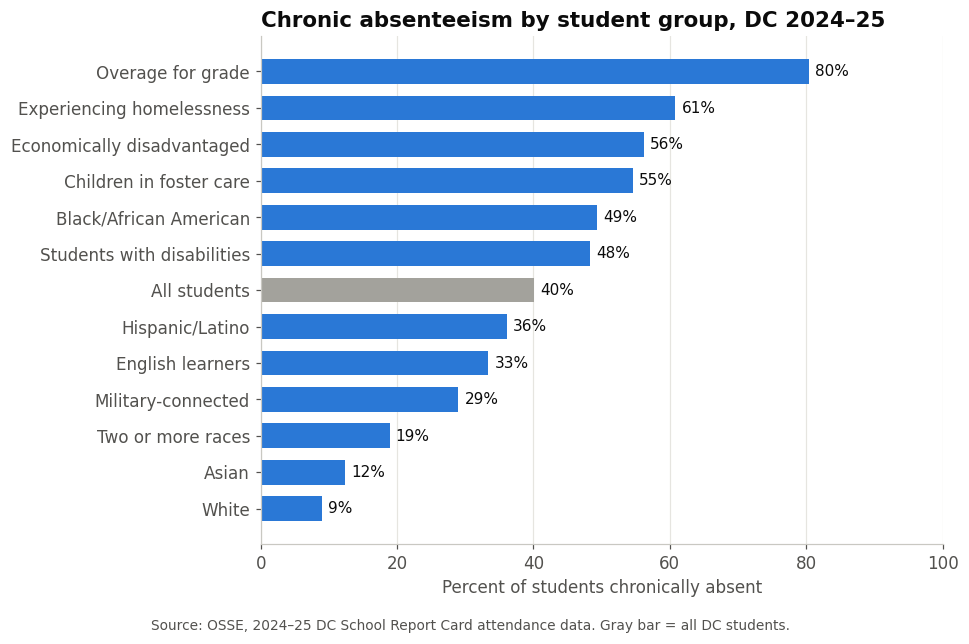

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = [GRAY if g == "All students" else BLUE for g in by_group["group"]]
bars = ax.barh(by_group["group"], by_group["rate"], color=colors, height=0.68)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in by_group["rate"]], padding=4, color=INK, fontsize=10)
ax.set_xlim(0, 100)
ax.set_xlabel("Percent of students chronically absent")
ax.grid(axis="y", visible=False)
ax.set_title("Chronic absenteeism by student group, DC 2024–25")
fig.text(0.0, -0.02, "Source: OSSE, 2024–25 DC School Report Card attendance data. Gray bar = all DC students.",
         fontsize=9, color=MUTED)
fig.savefig("images/1_student_groups.png")
plt.show()

**Finding:** Absenteeism follows **economic hardship**. More than half of economically disadvantaged students (56%) and students experiencing homelessness (61%) were chronically absent, compared with 9% of White students. Nearly half of Black students (49%) and students with disabilities (48%) were chronically absent. Students who are overage for their grade, often students who have been held back, have the highest rate at 80%.

> **Interview question:** *"Does this mean poverty causes absenteeism?"*
> Not by itself. This data shows a strong **link**, not a cause. Poverty often comes with barriers that make attendance harder, such as unstable housing, transportation problems, health issues, and caring for siblings. Finding out which barriers matter most at a given school needs student-level data and conversations with families.

## Step 6. At which grade levels does absenteeism rise?

OSSE groups schools into elementary, middle, high, and alternative schools. Alternative schools serve students who need a different path, such as students returning to school or older students finishing a diploma.

In [10]:
levels = ["Elementary School", "Middle School", "High School", "Alternative School"]
by_level = (state_by_level[state_by_level["Student Group"] == ALL]
            .set_index("School Framework").loc[levels, ["rate", "students"]])
by_level

,rate,students
School Framework,,
Elementary School,32.4,41858.0
Middle School,33.8,18964.0
High School,54.6,20963.0
Alternative School,85.4,2911.0


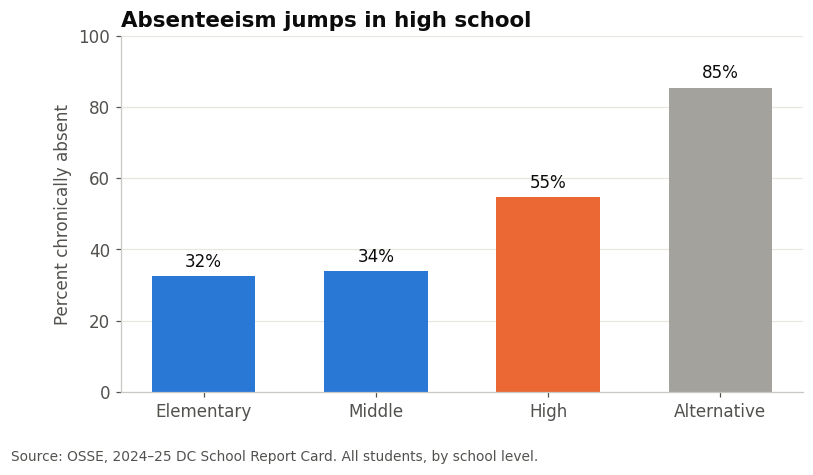

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = ["Elementary", "Middle", "High", "Alternative"]
colors = [BLUE, BLUE, ORANGE, GRAY]
bars = ax.bar(labels, by_level["rate"], color=colors, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in by_level["rate"]], padding=4, color=INK)
ax.set_ylim(0, 100)
ax.set_ylabel("Percent chronically absent")
ax.grid(axis="x", visible=False)
ax.set_title("Absenteeism jumps in high school")
fig.text(0.0, -0.04, "Source: OSSE, 2024–25 DC School Report Card. All students, by school level.",
         fontsize=9, color=MUTED)
fig.savefig("images/2_school_level.png")
plt.show()

**Finding:** Rates are similar in elementary (32%) and middle school (34%), then jump to **55% in high school**. That means more than half of DC high school students missed at least 10% of the year. The move into high school is the point where attendance breaks down.

In [12]:
# How severe is it? The fall file splits high school students by how much school they missed.
tiers = pd.read_excel(FALL, sheet_name="Risk Tiers", dtype=str)
tiers["percent"] = to_number(tiers["Percentage"])
tiers.query("`School Year` == '2024-25' and `Grade Band` == '9-12'")[["Absenteeism Risk Tier", "percent", "Students"]]

,Absenteeism Risk Tier,percent,Students
40,Satisfactory Attendance (missed <5%),35.7,7998
42,At-risk Attendance (missed 5%-9.99%),21.6,4844
44,Moderate Chronic Absence (missed 10%-19.99%),19.5,4360
46,Severe Chronic Absence (missed 20%-29.99%),7.9,1772
48,Profound Chronic Absence (missed 30%+),15.3,3419


Even in the first months of the 2024–25 year, about **15% of high school students had already missed 30% or more of school days**. That's roughly one day in three. Students at this level need intensive, one-on-one support, not just general reminders about attendance.

## Step 7. How much do schools differ?

In [13]:
school_rates = schools[schools["Student Group"] == ALL][["School Code", "School Name", "LEA Name", "rate", "students"]].dropna(subset=["rate"])
print("Schools:", len(school_rates))
print("Median school rate:", school_rates["rate"].median(), "%")
for cutoff in [30, 50]:
    count = (school_rates["rate"] >= cutoff).sum()
    print(f"Schools at {cutoff}% or higher: {count} ({count / len(school_rates):.0%})")

Schools: 229
Median school rate: 41.0 %
Schools at 30% or higher: 162 (71%)
Schools at 50% or higher: 64 (28%)


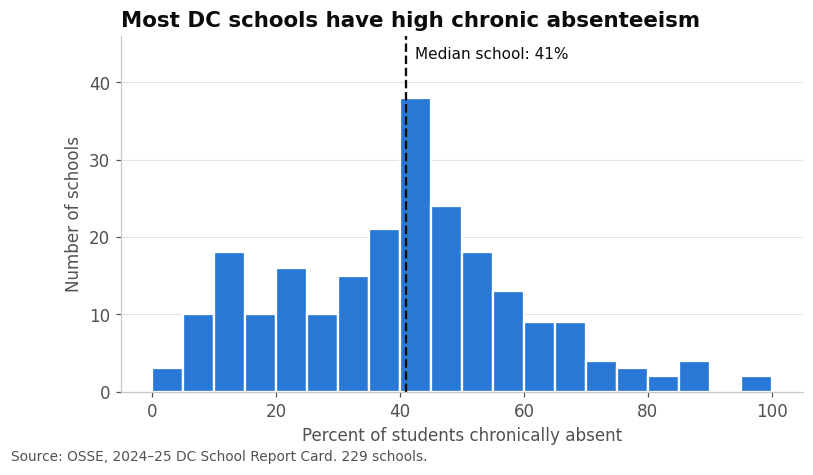

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(school_rates["rate"], bins=range(0, 105, 5), color=BLUE, edgecolor="white", linewidth=1.5)
median = school_rates["rate"].median()
ax.axvline(median, color=INK, linewidth=1.5, linestyle="--")
ax.set_ylim(0, 46)
ax.text(median + 1.5, 43, f"Median school: {median:.0f}%", color=INK, fontsize=10)
ax.set_xlabel("Percent of students chronically absent")
ax.set_ylabel("Number of schools")
ax.grid(axis="x", visible=False)
ax.set_title("Most DC schools have high chronic absenteeism")
fig.text(0.0, -0.04, f"Source: OSSE, 2024–25 DC School Report Card. {len(school_rates)} schools.",
         fontsize=9, color=MUTED)
fig.savefig("images/3_school_distribution.png")
plt.show()

**Finding:** At the typical DC school, **41%** of students were chronically absent. At 64 schools (28%), at least half of all students were chronically absent. Rates range from under 5% to over 95%, so where a student goes to school matters a great deal.

## Step 8. Which schools beat the odds?

Ranking schools by their raw rate isn't fair, because schools serving more students facing hardship will usually have higher absenteeism. A better question is: **which schools do much better than we'd expect, given the students they serve?**

**How we measure it:**

1. For each school, we calculate the **share of students who are economically disadvantaged**. The file doesn't give this directly, but it gives the number of students in each group, so we divide the number of economically disadvantaged students by the total.
2. We fit a straight **trend line** showing the expected absenteeism rate for a given share of disadvantaged students.
3. A school's **gap** is its actual rate minus its expected rate. A large negative gap means the school is doing much better than expected.

We leave out alternative schools and the one online school, because they work very differently from regular schools, and schools with fewer than 100 students.

In [15]:
# Step 8a: share of economically disadvantaged students at each school
econ = (schools[schools["Student Group"] == "Economically Disadvantaged"]
        [["School Code", "students", "rate"]]
        .rename(columns={"students": "econ_students", "rate": "econ_rate"}))
odds = school_rates.merge(econ, on="School Code", how="left")
odds["pct_econ"] = odds["econ_students"] / odds["students"] * 100

# Step 8b: leave out alternative schools, the online school, and very small schools
odds = odds[~odds["School Code"].isin(alternative_schools)
            & ~odds["School Name"].str.contains("Online")
            & (odds["students"] >= 100)].dropna(subset=["pct_econ"])
print("Schools in this comparison:", len(odds))
print("Correlation between % disadvantaged and absenteeism:", round(odds["pct_econ"].corr(odds["rate"]), 2))

Schools in this comparison: 213
Correlation between % disadvantaged and absenteeism: 0.75


In [16]:
# Step 8c: fit the trend line and measure each school's gap
slope, intercept = np.polyfit(odds["pct_econ"], odds["rate"], 1)
odds["expected"] = intercept + slope * odds["pct_econ"]
odds["gap"] = odds["rate"] - odds["expected"]
print(f"Each 10-point increase in disadvantaged students goes with about {slope * 10:.1f} more points of absenteeism.")

beat_the_odds = odds[odds["pct_econ"] >= 50].nsmallest(8, "gap")
beat_the_odds[["School Name", "LEA Name", "pct_econ", "rate", "expected", "gap"]].round(1)

Each 10-point increase in disadvantaged students goes with about 5.6 more points of absenteeism.


,School Name,LEA Name,pct_econ,rate,expected,gap
192,Richard Wright PCS for Journalism and Media Arts,Richard Wright PCS for Journalism and Media Arts,61.5,6.0,42.7,-36.7
39,DC Prep PCS - Anacostia Elementary School,DC Prep PCS,75.3,25.3,50.5,-25.2
34,Garfield Elementary School,District of Columbia Public Schools,88.0,34.7,57.5,-22.8
201,Cedar Tree Academy PCS,Cedar Tree Academy PCS,76.4,28.3,51.1,-22.8
195,Friendship PCS - Blow Pierce Middle,Friendship PCS,69.5,25.5,47.3,-21.8
124,Washington Global PCS,Washington Global PCS,63.2,24.6,43.7,-19.1
218,LaSalle-Backus Elementary School,District of Columbia Public Schools,67.9,30.1,46.3,-16.2
208,H.D. Cooke Elementary School,District of Columbia Public Schools,64.4,28.4,44.4,-16.0


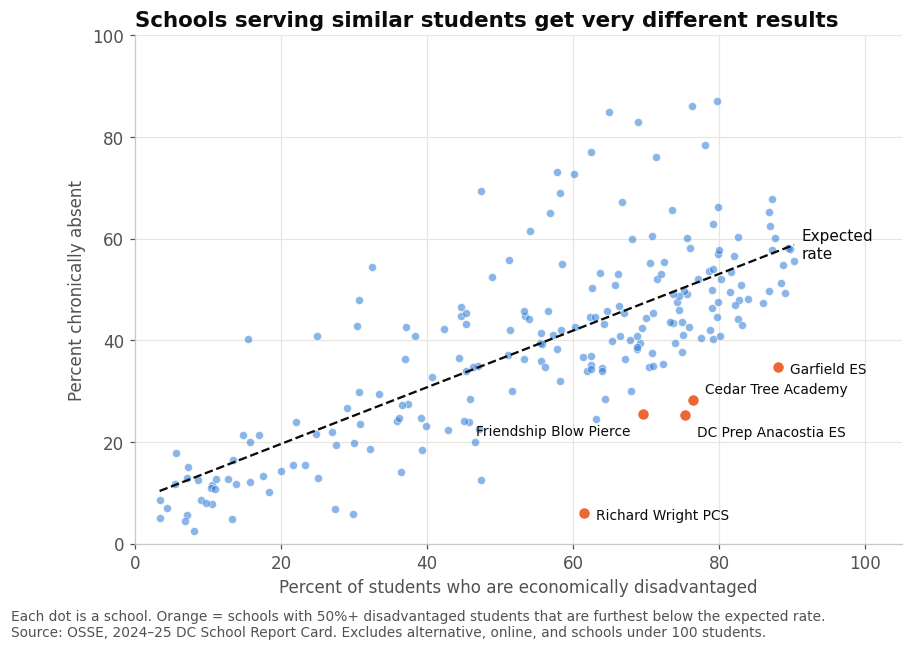

In [17]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(odds["pct_econ"], odds["rate"], s=28, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.6)
x = np.array([odds["pct_econ"].min(), odds["pct_econ"].max()])
ax.plot(x, intercept + slope * x, color=INK, linewidth=1.5, linestyle="--")
ax.text(x[1] + 1, intercept + slope * x[1], "Expected\nrate", ha="left", va="center", color=INK, fontsize=10)
top = beat_the_odds.head(5)
ax.scatter(top["pct_econ"], top["rate"], s=70, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=3)
# Short names and label positions chosen by hand so labels don't overlap
short = {"Richard Wright PCS for Journalism and Media Arts": ("Richard Wright PCS", (8, -4), "left"),
         "DC Prep PCS - Anacostia Elementary School": ("DC Prep Anacostia ES", (8, -14), "left"),
         "Garfield Elementary School": ("Garfield ES", (8, -4), "left"),
         "Cedar Tree Academy PCS": ("Cedar Tree Academy", (8, 4), "left"),
         "Friendship PCS - Blow Pierce Middle": ("Friendship Blow Pierce", (-8, -14), "right")}
for _, row in top.iterrows():
    name, offset, align = short.get(row["School Name"], (row["School Name"], (8, -4), "left"))
    ax.annotate(name, (row["pct_econ"], row["rate"]), xytext=offset, textcoords="offset points",
                fontsize=9, color=INK, ha=align)
ax.set_xlim(0, 105); ax.set_ylim(0, 100)
ax.set_xlabel("Percent of students who are economically disadvantaged")
ax.set_ylabel("Percent chronically absent")
ax.set_title("Schools serving similar students get very different results")
fig.text(0.0, -0.03, "Each dot is a school. Orange = schools with 50%+ disadvantaged students that are furthest below the expected rate.\n"
         "Source: OSSE, 2024–25 DC School Report Card. Excludes alternative, online, and schools under 100 students.",
         fontsize=9, color=MUTED)
fig.savefig("images/4_beat_the_odds.png")
plt.show()

**Finding:** The share of disadvantaged students is strongly linked to absenteeism (correlation of about 0.75). But schools serving very similar students still get very different results. The five schools highlighted in orange have absenteeism rates **22 to 37 points below** what we'd expect. These are the schools other schools should learn from.

**A careful analyst checks before celebrating.** A gap this large can come from strong practices, but also from changes in how attendance was recorded, a change in enrollment, or a special program. The next step would be to talk with these schools and find out what they do differently.

> **Interview question:** *"Why not just rank schools by their absenteeism rate?"*
> Because that mostly ranks schools by how many students facing hardship they serve. Comparing each school with its expected rate shows which schools are adding value.

## Step 9. Is attendance getting better?

The fall file compares the first months of 2024–25 (July–November 2024) with the same weeks a year earlier. Note that these early-year rates are lower than full-year rates, because absences build up over the year. We compare **fall with fall** so it's a fair comparison.

In [18]:
bands = ["K-2", "3-5", "6-8", "9-12"]
fall_all = fall_state[fall_state["Student Group"] == "All"].set_index("Grade Band")
trend = pd.DataFrame({
    "Fall 2023": to_number(fall_all.loc[bands, "% Chronically Absent (23-24)"]),
    "Fall 2024": to_number(fall_all.loc[bands, "% Chronically Absent (24-25)"]),
})
trend["change"] = trend["Fall 2024"] - trend["Fall 2023"]
trend

,Fall 2023,Fall 2024,change
Grade Band,,,
K-2,28.0,23.3,-4.7
3-5,23.7,20.8,-2.9
6-8,26.6,24.7,-1.9
9-12,45.4,42.7,-2.7


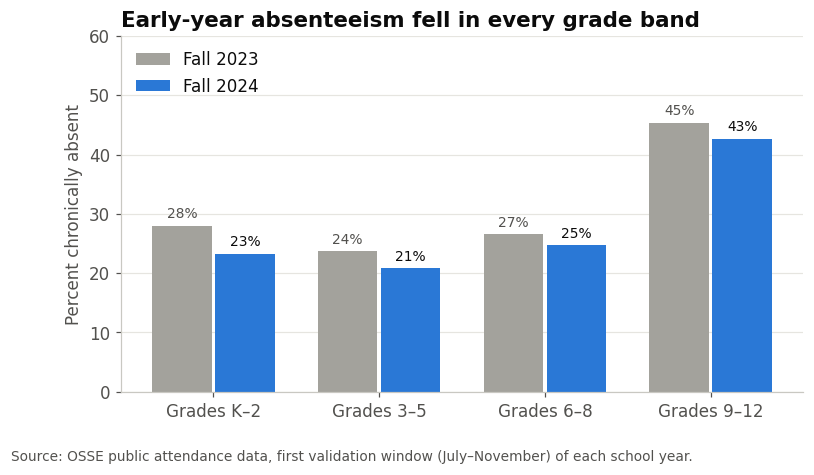

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.2))
pos = np.arange(len(bands))
w = 0.36
b1 = ax.bar(pos - w / 2 - 0.01, trend["Fall 2023"], w, color=GRAY, label="Fall 2023")
b2 = ax.bar(pos + w / 2 + 0.01, trend["Fall 2024"], w, color=BLUE, label="Fall 2024")
ax.bar_label(b1, labels=[f"{v:.0f}%" for v in trend["Fall 2023"]], padding=3, color=MUTED, fontsize=9)
ax.bar_label(b2, labels=[f"{v:.0f}%" for v in trend["Fall 2024"]], padding=3, color=INK, fontsize=9)
ax.set_xticks(pos, ["Grades K–2", "Grades 3–5", "Grades 6–8", "Grades 9–12"])
ax.set_ylim(0, 60)
ax.set_ylabel("Percent chronically absent")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Early-year absenteeism fell in every grade band")
fig.text(0.0, -0.04, "Source: OSSE public attendance data, first validation window (July–November) of each school year.",
         fontsize=9, color=MUTED)
fig.savefig("images/5_fall_trend.png")
plt.show()

In [20]:
# How many schools improved?
fall_schools["rate"] = to_number(fall_schools["% Chronically Absent (K-12)"])
by_school = fall_schools.pivot_table(index="School Code", columns="School Year", values="rate").dropna()
by_school["change"] = by_school["2024-25"] - by_school["2023-24"]
improved = (by_school["change"] < 0).sum()
print(f"{improved} of {len(by_school)} schools ({improved / len(by_school):.0%}) had lower early-year absenteeism in 2024 than 2023.")
print("Median change:", by_school["change"].median(), "points")

161 of 229 schools (70%) had lower early-year absenteeism in 2024 than 2023.
Median change: -3.0 points


**Finding:** Early-year absenteeism dropped in every grade band, with the biggest drop in grades K–2 (28% to 23%). About **7 in 10 schools** improved. DC is moving in the right direction, but high school rates are still very high.

## Step 10. Summary and recommendations

**Key findings**

1. **About 4 in 10 DC students (40%) were chronically absent in 2024–25.**
2. **Absenteeism tracks economic hardship.** 56% of economically disadvantaged students and 61% of students experiencing homelessness were chronically absent, compared with 9% of White students.
3. **High school is the breaking point.** Rates jump from 34% in middle school to 55% in high school.
4. **Schools vary widely, even when they serve similar students.** Five schools where most students are economically disadvantaged have rates 22 to 37 points below what we'd expect.
5. **Things are improving.** Early-year absenteeism fell in every grade band, and about 7 in 10 schools improved from fall 2023 to fall 2024.

**Recommendations for school and district leaders**

1. **Focus on the move into high school.** Use 8th-grade attendance to identify students at risk before they start 9th grade, and give each one an adult mentor who checks in during the first weeks of high school.
2. **Remove practical barriers for students facing hardship.** For students who are economically disadvantaged or experiencing homelessness, the barriers are often practical: transportation, health, and housing. Pair attendance data with family outreach to find out which barriers matter most at each school.
3. **Learn from schools that beat the odds.** Visit the schools that do much better than expected, document what they do, and share those practices with similar schools.

## Limitations

- This is **school-level** public data, so it shows patterns across schools, not why individual students miss school.
- Correlation is not causation. The economic-disadvantage link shows where to look, not what causes absences.
- The "expected rate" uses only one factor. A fuller model would also account for school level (elementary, middle, high) and other student needs.
- Suppressed values (small groups) were left out, not estimated.
- The fall comparison covers only the first months of each school year.

## Data sources

- OSSE, *2024–25 Chronic Absenteeism Metric Scores* (DC School Report Card attendance data).
- OSSE, *Attendance Data Public Reporting* (first validation window, July–November 2024 and 2023).
- Both available at [osse.dc.gov/page/2024-25-school-year-attendance-reporting](https://osse.dc.gov/page/2024-25-school-year-attendance-reporting).